# Lab: Build, Train, and Evaluate a Machine Learning Pipeline for Predicting Customer Churn

### Lab Objectives:

- Perform **exploratory data analysis (EDA)** to understand patterns in the dataset.
- Build a **supervised learning pipeline** for churn prediction.
- Evaluate the model using metrics like **precision, recall, and F1-score**.
- Prepare a short **"client update"** summarizing key insights and proposed actions.

## Scenario:
Your retail client has provided customer behavior data and needs a predictive model to identify at-risk customers. Your task is to build the model and prepare a presentation summarizing findings and recommendations.

## Task 1: Perform EDA to understand patterns in the dataset.
In this section, we'll explore the retail sales dataset to identify patterns, understand customer behavior, and gain insights that will help us develop a churn prediction model.

**Import necessary libraries**

In [2]:
# TODO: Import numpy as np
import numpy as np

In [3]:
# TODO: Import pandas as pd
import pandas as pd

In [4]:
# TODO: Import matplotlib.pyplot as plt
import matplotlib.pyplot as plt 

In [5]:
# TODO: Import seaborn as sns
import seaborn as sns

**Load the Dataset**

In [6]:
# TODO: Load the retail sales data using pd.read_csv()
df = pd.read_csv("data/retail-sales-data.csv")

In [7]:
# TODO: Display the first few rows of the dataset using head()
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


**Display basic statistics and check for missing values**

In [8]:
# TODO: Use info() to get a summary of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [9]:
# TODO: Use describe() to get statistical information
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [10]:
# TODO: Check for missing values using isnull().sum()
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

**Cleaning and Transforming Data**

Now that we have an overview of the data, let's perform some preprocessing steps to prepare it for analysis.

In [11]:
# TODO: Drop unnecessary columns like 'Transaction ID' and 'Customer ID'
df = df.drop(columns=['Transaction ID', 'Customer ID'])

In [12]:
# TODO: Convert date column to datetime format using pd.to_datetime()
df['Date'] = pd.to_datetime(df['Date']) 

**Visualize Key Patterns**

In [13]:
# TODO: Group data by Gender and calculate mean and sum of Total Amount
gender_spend = df.groupby('Gender')['Total Amount'].agg(['mean', 'sum'])
print (gender_spend)

              mean     sum
Gender                    
Female  456.549020  232840
Male    455.428571  223160


In [14]:
# TODO: Create a bar plot to visualize spending by gender
gender_spend['sum'].plot(kind='bar')
plt.title('total spending by gender')
plt.ylabel('Total Amount')
plt.show()

<Figure size 640x480 with 1 Axes>

In [15]:
# TODO: Print the gender spending statistics
print(gender_spend['sum'])

Gender
Female    232840
Male      223160
Name: sum, dtype: int64


**Group by Age Bins**

Let's segment customers by age groups to understand spending patterns across different demographics.

In [16]:
# TODO: Create age groups using pd.cut()
df['Age Groups'] = pd.cut(df['Age'], bins=[17,25,35,45,55,99], labels = ['18-25', '26-35', '36-45', '46-55', '56++'])

In [17]:
# TODO: Group by age groups and calculate mean of Total Amount
age_spend = df.groupby('Age Groups', observed=True) ['Total Amount'].mean()

In [18]:
# TODO: Print age group spending statistics
print(age_spend)

Age Groups
18-25    500.295858
26-35    480.390244
36-45    454.801980
46-55    439.694323
56++     412.358974
Name: Total Amount, dtype: float64


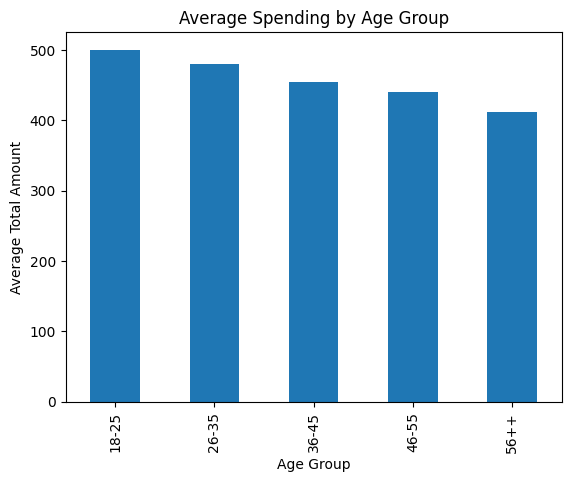

In [19]:
# TODO: Create a bar plot of average spending by age group with appropriate labels and colors
age_spend.plot(kind='bar')
plt.title('Average Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Total Amount')
plt.show()

**Analyze monthly sales trends and weekday vs. weekend sales**

Understanding sales patterns over time and days of the week can provide valuable insights for business strategy.

In [20]:
# TODO: Extract month from Date column
df['Month'] = df['Date'].dt.month

In [21]:
# TODO: Group by Month and calculate sum of Total Amount
monthly_sales = df.groupby('Month')['Total Amount'].sum()

In [22]:
# TODO: Print monthly sales statistics
print (monthly_sales)

Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


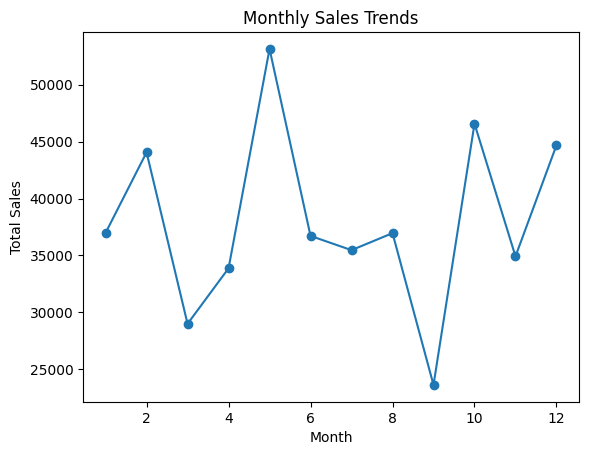

In [23]:
# TODO: Create a line plot showing monthly sales trends
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales Trends')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

In [24]:
# TODO: Extract day name from Date column
df['Day'] = df['Date'].dt.day_name()

In [25]:
# TODO: Group by weekday and calculate sum of Total Amount
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = df.groupby('Day')['Total Amount'].sum().reindex(days)

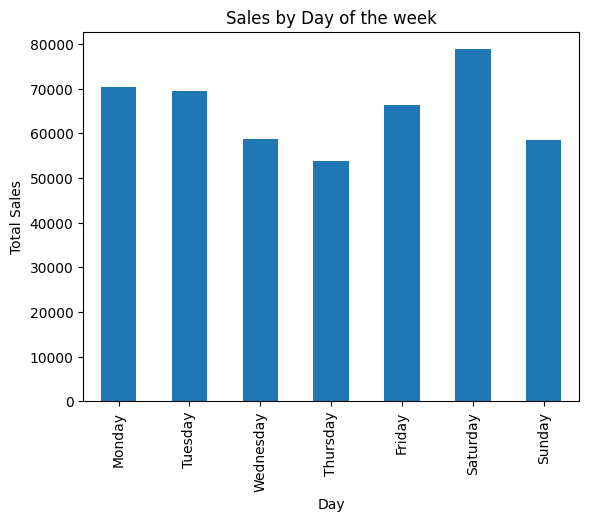

In [26]:
# TODO: Create a bar plot to visualize sales by day of the week
weekday_sales.plot(kind='bar')
plt.title('Sales by Day of the week')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.show()

In [27]:
# TODO: Print weekday sales statistics
print(weekday_sales)

Day
Monday       70250
Tuesday      69440
Wednesday    58770
Thursday     53835
Friday       66290
Saturday     78815
Sunday       58600
Name: Total Amount, dtype: int64


**Analyse the months with maximum and minimum sales**

Identifying peak and low sales periods can help with inventory planning and marketing strategies.

In [28]:
# TODO: Find the month with maximum sales using idxmax()
max_month = monthly_sales.idxmax()
print(max_month)

5


In [29]:
# TODO: Get the maximum sales amount using max()
max_sales = monthly_sales.max()
print(max_sales)

53150


In [30]:
# TODO: Find the month with minimum sales using idxmin()
min_month = monthly_sales.idxmin()
print(min_month)

9


In [31]:
# TODO: Get the minimum sales amount using min()
min_sales = monthly_sales.min()
print(min_sales)

23620


In [32]:
# TODO: Print the months with maximum and minimum sales
print(max_month, min_month)

5 9


**Quantities Purchased By Categories**

Let's analyze which product categories are most popular with customers in terms of quantities purchased.

In [33]:
# TODO: Group by Product Category and calculate sum of Quantity
category_qty = df.groupby('Product Category')['Quantity'].sum()

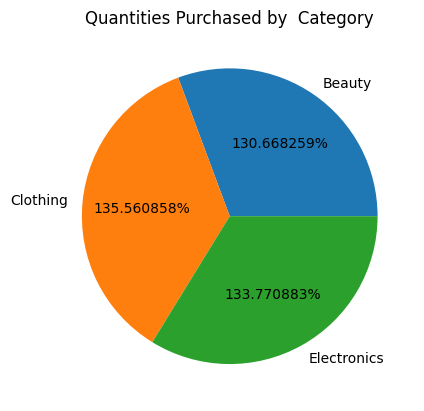

In [34]:
# TODO: Create a pie chart showing quantities purchased by category
category_qty.plot(kind='pie', autopct='1%1f%%')
plt.title('Quantities Purchased by  Category')
plt.ylabel('')
plt.show()

In [35]:
# TODO: Add appropriate title and labels to the pie chart

## Task 2: Build the Churn Prediction Pipeline

In this section, we'll build a machine learning pipeline to predict customer churn based on their purchasing behavior.

**Import required libraries for modeling**

In [36]:
# TODO: Import train_test_split from sklearn.model_selection
from sklearn.model_selection import train_test_split

In [37]:
# TODO: Import LinearRegression from sklearn.linear_model
from sklearn.linear_model import LinearRegression

In [38]:
# TODO: Import StandardScaler from sklearn.preprocessing
from sklearn.preprocessing import StandardScaler

In [39]:
# TODO: Import metrics like mean_squared_error, r2_score, classification_report, accuracy_score
from sklearn.metrics import mean_squared_error, r2_score, classification_report, accuracy_score

**Prepare the data for modeling**

In [40]:
# TODO: Select relevant features (Age, Quantity, Price per Unit)
X = df[['Age', 'Quantity', 'Price per Unit']]

In [41]:
# TODO: Define target variable (Total Amount)
y = df['Total Amount']

In [42]:
# TODO: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [43]:
# TODO: Standardize the features using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [44]:
# TODO: Import RandomForestClassifier from sklearn.ensemble
from sklearn.ensemble import RandomForestClassifier

In [45]:
# TODO: Instantiate the classifier
model = RandomForestClassifier(random_state=42)

In [46]:
# TODO: Fit the model to the training data
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [47]:
# TODO: Make predictions on the test data
y_pred = model.predict(X_test)

In [48]:
# TODO: Calculate and print the accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

1.0


**Train a linear regression model**

In [49]:
# TODO: Instantiate the LinearRegression model
lr_model = LinearRegression()

In [50]:
# TODO: Fit the model to the training data
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-12.31,202.75,471.75]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,454.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[29.38,27.99,27.44]"


In [51]:
# TODO: Make predictions on the test data
lr_pred = lr_model.predict(X_test)

In [52]:
# TODO: Print model performance metrics (MSE and R-squared)
mse = mean_squared_error(y_test, lr_pred)
r2 = r2_score(y_test, lr_pred)
print (mse, r2)

41896.21322134363 0.856877226425043


## Task 3: Evaluate the model using metrics like precision, recall, and F1-score.

Let's evaluate our model's performance using various metrics to understand how well it predicts customer churn.

In [ ]:
# TODO: Calculate Mean Squared Error using mean_squared_error
mse = mean_squared_error(y_test, lr_pred)

In [ ]:
# TODO: Calculate R-squared score using r2_score
r2 = r2_score(y_test, lr_pred)

In [53]:
# TODO: Convert target variables to integer type if necessary
y_test = y_test.astype(int)
y_pred = y_pred.astype(int)

In [54]:
# TODO: Print classification report to see precision, recall, and F1-score
print (classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          25       1.00      1.00      1.00        10
          30       1.00      1.00      1.00         7
          50       1.00      1.00      1.00        17
          60       1.00      1.00      1.00         9
          75       1.00      1.00      1.00         8
          90       1.00      1.00      1.00         9
         100       1.00      1.00      1.00        23
         120       1.00      1.00      1.00         7
         150       1.00      1.00      1.00         9
         200       1.00      1.00      1.00        17
         300       1.00      1.00      1.00        15
         500       1.00      1.00      1.00         8
         600       1.00      1.00      1.00         5
         900       1.00      1.00      1.00        14
        1000       1.00      1.00      1.00        12
        1200       1.00      1.00      1.00        10
        1500       1.00      1.00      1.00        13
        2000       1.00    

In [56]:
# TODO: Import confusion_matrix from sklearn.metrics
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

In [57]:
# TODO: Calculate and print the confusion matrix to visualize model predictions
print (cm)

[[10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  7  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  9  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 23  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  7  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  9  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 17  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 15  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  8  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  5  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0 14  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 12  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 10  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 13  0]
 [ 0  0  0  0  0  0  0  0  0  0

In this lab, we have analyzed retail sales data to understand customer purchasing patterns and built a predictive model for customer churn. We first conducted exploratory data analysis (EDA) to identify patterns in customer behavior across demographics, time periods, and product categories. Then, we developed a machine learning pipeline using various algorithms to predict which customers are likely to churn. Finally, we evaluated the model's performance using appropriate metrics and suggested strategies to reduce customer churn based on our findings. This lab demonstrated how data analysis and machine learning can help businesses make informed decisions to improve customer retention.